# Why I am doing this project?

This project uses Natural Language Processing (NLP) and unsupervised learning to automatically group news articles into meaningful topics. The text data is cleaned and preprocessed before converting articles into numerical features using TF-IDF. K-Means clustering is then used to discover groups of similar articles, with the Elbow Method and Silhouette Score used to determine the appropriate number of clusters. The project also includes data visualization and a Streamlit application for interactive topic clustering.

Through this project, I want to use Data Science and Machine Learning techniques to:

1. **Learn NLP** – I work with real text data and learn text cleaning and preprocessing.
2. **Learn TF-IDF** – I convert news articles into numerical features that ML algorithms can understand.
3. **Practice Unsupervised Learning** – Instead of giving the model predefined topics, K-Means discovers groups by itself.
4. **Understand Clustering** – I learn how to determine the best number of clusters using Elbow Method and Silhouette Score.
5. **Build a real-world application** – News websites can automatically group thousands of articles into topics such as Sports, Business, Technology, etc.
6. **Improve my portfolio** – I already have supervised ML projects and sentiment-analysis projects; this adds NLP + clustering to your portfolio.

**Business Problem**

News organizations receive thousands of articles from different sources every day. Manually organizing these articles into topics can be time-consuming and difficult to scale.

The goal of this project is to develop a system that can automatically group similar news articles into meaningful topics without using predefined topic labels during model training.

## Dataset Description

The **AG News Dataset** is a collection of news articles categorized into four major topics: **World, Sports, Business, and Sci/Tech**. Each record contains a **title, description, and category label**. In this project, the title and description are combined and used as the main text for NLP preprocessing and clustering. The category labels are not used to train the K-Means model; they are kept only for understanding and evaluating the resulting clusters.

**Source:** [Dataset Link](https://www.kaggle.com/datasets/amananandrai/ag-news-classification-dataset?)

# TASK #1: IMPORT LIBRARIES AND DATASET

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# loading the dataset
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

news_df = pd.concat([train, test], ignore_index=True)

print(news_df.shape)

(127600, 3)


In [3]:
news_df.head()

,Class Index,Title,Description
0,3,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli..."
1,3,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...
2,3,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...
3,3,Iraq Halts Oil Exports from Main Southern Pipe...,Reuters - Authorities have halted oil export\f...
4,3,"Oil prices soar to all-time record, posing new...","AFP - Tearaway world oil prices, toppling reco..."


In [4]:
news_df.tail()

,Class Index,Title,Description
127595,1,Around the world,Ukrainian presidential candidate Viktor Yushch...
127596,2,Void is filled with Clement,With the supply of attractive pitching options...
127597,2,Martinez leaves bitter,Like Roger Clemens did almost exactly eight ye...
127598,3,5 of arthritis patients in Singapore take Bext...,SINGAPORE : Doctors in the United States have ...
127599,3,EBay gets into rentals,EBay plans to buy the apartment and home renta...


In [5]:
news_df.dtypes

Class Index     int64
Title          object
Description    object
dtype: object

In [6]:
news_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 127600 entries, 0 to 127599
Data columns (total 3 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   Class Index  127600 non-null  int64 
 1   Title        127600 non-null  object
 2   Description  127600 non-null  object
dtypes: int64(1), object(2)
memory usage: 2.9+ MB


In [7]:
news_df.describe(include="all")

,Class Index,Title,Description
count,127600.000000,127600,127600
unique,NaN,121258,126182
top,NaN,Today's schedule,"With the economy slowly turning up, upgrading ..."
freq,NaN,43,16
mean,2.500000,NaN,NaN
std,1.118038,NaN,NaN
min,1.000000,NaN,NaN
25%,1.750000,NaN,NaN
50%,2.500000,NaN,NaN
75%,3.250000,NaN,NaN


# TASK #2: EXPLORING DATA AND PERFORMING DATA CLEANING

<Axes: >

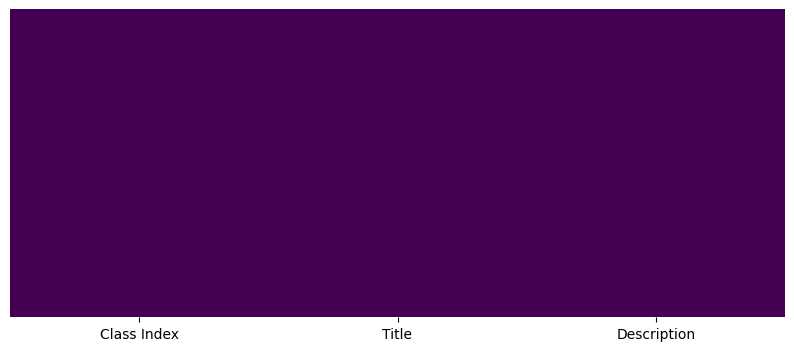

In [8]:
# Checking the missing values
plt.figure(figsize=(10, 4))
sns.heatmap(news_df.isnull(), yticklabels=False, cbar=False, cmap='viridis')

In [9]:
# Checking the missing values wih a sum()
news_df.isnull().sum()

Class Index    0
Title          0
Description    0
dtype: int64

In [10]:
# Checking the duplicate rows
news_df.duplicated().sum()

np.int64(0)

In [11]:
# Checking the description columns
news_df['Description'].head(10)

0    Reuters - Short-sellers, Wall Street's dwindli...
1    Reuters - Private investment firm Carlyle Grou...
2    Reuters - Soaring crude prices plus worries\ab...
3    Reuters - Authorities have halted oil export\f...
4    AFP - Tearaway world oil prices, toppling reco...
5    Reuters - Stocks ended slightly higher on Frid...
6    AP - Assets of the nation's retail money marke...
7    USATODAY.com - Retail sales bounced back a bit...
8    Forbes.com - After earning a PH.D. in Sociolog...
9     NEW YORK (Reuters) - Short-sellers, Wall Stre...
Name: Description, dtype: object

In [12]:
# Identifying the text Columns
text_columns = news_df.select_dtypes(include='object').columns 

In [13]:
text_columns

Index(['Title', 'Description'], dtype='object')

In [14]:
news_df['Title'] = news_df['Title'].fillna("")
news_df['Description'] = news_df['Description'].fillna("")

In [15]:
# Creating a new column 'text' by combining the 'Title' and 'Description' columns
news_df['text'] = news_df['Title'] + " " + news_df['Description']

In [16]:
news_df[['Title', 'Description', 'text']].head(10)

,Title,Description,text
0,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli...",Wall St. Bears Claw Back Into the Black (Reute...
1,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...,Carlyle Looks Toward Commercial Aerospace (Reu...
2,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...,Oil and Economy Cloud Stocks' Outlook (Reuters...
3,Iraq Halts Oil Exports from Main Southern Pipe...,Reuters - Authorities have halted oil export\f...,Iraq Halts Oil Exports from Main Southern Pipe...
4,"Oil prices soar to all-time record, posing new...","AFP - Tearaway world oil prices, toppling reco...","Oil prices soar to all-time record, posing new..."
5,"Stocks End Up, But Near Year Lows (Reuters)",Reuters - Stocks ended slightly higher on Frid...,"Stocks End Up, But Near Year Lows (Reuters) Re..."
6,Money Funds Fell in Latest Week (AP),AP - Assets of the nation's retail money marke...,Money Funds Fell in Latest Week (AP) AP - Asse...
7,Fed minutes show dissent over inflation (USATO...,USATODAY.com - Retail sales bounced back a bit...,Fed minutes show dissent over inflation (USATO...
8,Safety Net (Forbes.com),Forbes.com - After earning a PH.D. in Sociolog...,Safety Net (Forbes.com) Forbes.com - After ear...
9,Wall St. Bears Claw Back Into the Black,"NEW YORK (Reuters) - Short-sellers, Wall Stre...",Wall St. Bears Claw Back Into the Black NEW Y...


In [17]:
# Checking empty strings in the 'text' column
(news_df['text'].str.strip() == "").sum()

np.int64(0)

In [18]:
# Checking the length of the 'text' column
news_df['text_length'] = news_df['text'].str.len()

In [19]:
news_df['word_count'] = news_df['text'].str.split().apply(len)

In [20]:
news_df[['text', 'text_length', 'word_count']].head(10)

,text,text_length,word_count
0,Wall St. Bears Claw Back Into the Black (Reute...,144,21
1,Carlyle Looks Toward Commercial Aerospace (Reu...,266,36
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,232,36
3,Iraq Halts Oil Exports from Main Southern Pipe...,256,36
4,"Oil prices soar to all-time record, posing new...",234,37
5,"Stocks End Up, But Near Year Lows (Reuters) Re...",239,38
6,Money Funds Fell in Latest Week (AP) AP - Asse...,215,35
7,Fed minutes show dissent over inflation (USATO...,252,39
8,Safety Net (Forbes.com) Forbes.com - After ear...,414,68
9,Wall St. Bears Claw Back Into the Black NEW Y...,147,23


# TASK #3: EXPLORATORY DATA ANALYSIS (EDA)